In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Flood prediction project started successfully!")

Flood prediction project started successfully!


In [133]:


url = "https://github.com/BVPKARTHIKEYA/Flood_Risk_Prediction/raw/refs/heads/main/flood_risk_dataset_india.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 14)


,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465433,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [134]:
print("column names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("missing values:")
print(df.isnull().sum())
print("\ndataset description:")
display(df.describe())

column names:
['Latitude', 'Longitude', 'Rainfall (mm)', 'Temperature (°C)', 'Humidity (%)', 'River Discharge (m³/s)', 'Water Level (m)', 'Elevation (m)', 'Land Cover', 'Soil Type', 'Population Density', 'Infrastructure', 'Historical Floods', 'Flood Occurred']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Latitude                10000 non-null  float64
 1   Longitude               10000 non-null  float64
 2   Rainfall (mm)           10000 non-null  float64
 3   Temperature (°C)        10000 non-null  float64
 4   Humidity (%)            10000 non-null  float64
 5   River Discharge (m³/s)  10000 non-null  float64
 6   Water Level (m)         10000 non-null  float64
 7   Elevation (m)           10000 non-null  float64
 8   Land Cover              10000 non-null  object 
 9   Soil Type            

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,22.330627,82.631366,150.015118,29.961401,59.749104,2515.722946,5.017881,4417.138177,5021.468442,0.502000,0.498700,0.505700
std,8.341274,8.389542,86.032127,8.669838,23.142734,1441.706442,2.876579,2530.245421,2882.591520,0.500021,0.500023,0.499993
min,8.000337,68.004575,0.014437,15.000166,20.001339,0.042161,0.002701,1.150340,2.289000,0.000000,0.000000,0.000000
25%,15.143537,75.364428,76.124373,22.405717,39.541778,1284.782376,2.538847,2229.681903,2491.766601,0.000000,0.000000,0.000000
50%,22.283330,82.671007,150.620428,30.000907,59.497375,2530.451944,5.042094,4417.199761,5074.392879,1.000000,0.000000,1.000000
75%,29.460184,89.937897,223.402156,37.413488,80.038163,3767.229862,7.524692,6616.729066,7474.228752,1.000000,1.000000,1.000000
max,36.991813,96.997820,299.970293,44.993681,99.997772,4999.698480,9.996899,8846.894877,9999.169530,1.000000,1.000000,1.000000


In [135]:
print("Duplicate rows:", df.duplicated().sum())


df = df.drop_duplicates()


df = pd.get_dummies(
    df,
    columns=['Land Cover', 'Soil Type'],
    drop_first=True
)

# Separate input features and target
X = df.drop('Flood Occurred', axis=1)
y = df['Flood Occurred']

print("Data preprocessing completed!")
print("Input features:", X.shape)
print("Target:", y.shape)

print("\nFlood occurrence distribution:")
print(y.value_counts())

Duplicate rows: 0
Data preprocessing completed!
Input features: (10000, 19)
Target: (10000,)

Flood occurrence distribution:
Flood Occurred
1    5057
0    4943
Name: count, dtype: int64


In [136]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Data splitting completed!
Training records: 8000
Testing records: 2000


In [137]:


model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Flood Prediction Model Trained Successfully!")

Flood Prediction Model Trained Successfully!


In [138]:


y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 50.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.51      0.50       989
           1       0.51      0.50      0.50      1011

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000


Confusion Matrix:
[[502 487]
 [510 501]]


In [139]:


print("Flood distribution:")
print(y.value_counts())

print("\nFlood percentage:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining accuracy:")
print(model.score(X_train, y_train) * 100)

print("\nTesting accuracy:")
print(model.score(X_test, y_test) * 100)

print("\nFeature importance:")
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance)

Flood distribution:
Flood Occurred
1    5057
0    4943
Name: count, dtype: int64

Flood percentage:
Flood Occurred
1    50.57
0    49.43
Name: proportion, dtype: float64

Training accuracy:
100.0

Testing accuracy:
50.14999999999999

Feature importance:


,0
Humidity (%),0.102087
Temperature (°C),0.100049
Water Level (m),0.099674
River Discharge (m³/s),0.099565
Longitude,0.098706
Elevation (m),0.097848
Population Density,0.097618
Rainfall (mm),0.096693
Latitude,0.096538
Infrastructure,0.014153


In [140]:


correlation = df.corr(numeric_only=True)['Flood Occurred'].sort_values(
    ascending=False
)

print("Correlation with Flood Occurred:")
display(correlation)

print("\nFlood occurrence by rainfall:")
display(df.groupby(
    pd.cut(df['Rainfall (mm)'], bins=5, duplicates='drop')
)['Flood Occurred'].mean())

print("\nFlood occurrence by water level:")
display(df.groupby(
    pd.cut(df['Water Level (m)'], bins=5, duplicates='drop')
)['Flood Occurred'].mean())

Correlation with Flood Occurred:


,Flood Occurred
Flood Occurred,1.000000
Humidity (%),0.027754
Historical Floods,0.012030
Land Cover_Desert,0.010393
Land Cover_Urban,0.009591
Soil Type_Sandy,0.007497
Soil Type_Peat,0.005598
Land Cover_Forest,-0.001963
River Discharge (m³/s),-0.002115
Rainfall (mm),-0.002170



Flood occurrence by rainfall:


/tmp/ipykernel_1000/2330894522.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby(


,Flood Occurred
Rainfall (mm),
"(-0.286, 60.006]",0.515448
"(60.006, 119.997]",0.497802
"(119.997, 179.988]",0.510081
"(179.988, 239.979]",0.496128
"(239.979, 299.97]",0.509944



Flood occurrence by water level:


/tmp/ipykernel_1000/2330894522.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby(


,Flood Occurred
Water Level (m),
"(-0.00729, 2.002]",0.520260
"(2.002, 4.0]",0.507447
"(4.0, 5.999]",0.484789
"(5.999, 7.998]",0.497265
"(7.998, 9.997]",0.519202


In [141]:
!pip -q install gradio

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

# Get the input columns used during model training
feature_names = X.columns.tolist()

def predict_flood(latitude, longitude, rainfall, temperature,
                  humidity, river_discharge, water_level,
                  elevation, population_density, infrastructure,
                  historical_floods, land_cover, soil_type):

    # Create input data
    input_data = {
        'Latitude': latitude,
        'Longitude': longitude,
        'Rainfall (mm)': rainfall,
        'Temperature (°C)': temperature,
        'Humidity (%)': humidity,
        'River Discharge (m³/s)': river_discharge,
        'Water Level (m)': water_level,
        'Elevation (m)': elevation,
        'Population Density': population_density,
        'Infrastructure': infrastructure,
        'Historical Floods': historical_floods
    }

    # Add categorical columns using the training feature names
    for col in feature_names:
        if col.startswith('Land Cover_'):
            input_data[col] = int(col == f'Land Cover_{land_cover}')
        elif col.startswith('Soil Type_'):
            input_data[col] = int(col == f'Soil Type_{soil_type}')

    input_df = pd.DataFrame([input_data]).reindex(
        columns=feature_names, fill_value=0
    )

    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]
    confidence = max(probabilities) * 100

    if prediction == 1:
        result = "Flood predicted by the model"
    else:
        result = "No flood predicted by the model"

    return result, f"Model confidence: {confidence:.2f}%"

# Dashboard charts
def show_dashboard():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    y.value_counts().sort_index().plot(
        kind='bar', ax=axes[0], title='Flood Occurrence Distribution'
    )
    axes[0].set_xlabel('Flood Occurred (0 = No, 1 = Yes)')
    axes[0].set_ylabel('Number of Records')

    importance = pd.Series(
        model.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(10)

    importance.sort_values().plot(
        kind='barh', ax=axes[1], title='Top 10 Important Features'
    )
    axes[1].set_xlabel('Importance')

    plt.tight_layout()
    return fig

with gr.Blocks(title="AI Flood Prediction System") as demo:

    gr.Markdown("# AI-Based Flood Prediction and Early Warning System")
    gr.Markdown(
        "Enter environmental and location details to see the model's prediction."
    )

    with gr.Row():
        with gr.Column():
            latitude = gr.Number(label="Latitude", value=13.0)
            longitude = gr.Number(label="Longitude", value=77.0)
            rainfall = gr.Number(label="Rainfall (mm)", value=100)
            temperature = gr.Number(label="Temperature (°C)", value=28)
            humidity = gr.Number(label="Humidity (%)", value=75)
            river_discharge = gr.Number(label="River Discharge (m³/s)", value=500)

        with gr.Column():
            water_level = gr.Number(label="Water Level (m)", value=5)
            elevation = gr.Number(label="Elevation (m)", value=800)
            population_density = gr.Number(label="Population Density", value=1000)
            infrastructure = gr.Number(label="Infrastructure", value=1)
            historical_floods = gr.Number(label="Historical Floods", value=1)
            land_cover = gr.Dropdown(
                choices=['Agricultural', 'Desert', 'Forest', 'Urban'],
                label="Land Cover", value='Urban'
            )
            soil_type = gr.Dropdown(
                choices=['Clay', 'Loamy', 'Sandy'],
                label="Soil Type", value='Clay'
            )

    predict_button = gr.Button("Predict Flood")
    prediction_output = gr.Textbox(label="Prediction")
    confidence_output = gr.Textbox(label="Model confidence")

    predict_button.click(
        fn=predict_flood,
        inputs=[
            latitude, longitude, rainfall, temperature, humidity,
            river_discharge, water_level, elevation, population_density,
            infrastructure, historical_floods, land_cover, soil_type
        ],
        outputs=[prediction_output, confidence_output]
    )

    gr.Markdown("## Flood Data Dashboard")
    dashboard_button = gr.Button("Show Dashboard")
    dashboard_output = gr.Plot()
    dashboard_button.click(show_dashboard, outputs=dashboard_output)

    gr.Markdown(
        "**Important:** This is an educational prototype using a dataset "
        "that has not been verified as real-world observations. "
        "It must not be used for actual emergency decisions."
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4713b29d9d3c7f408a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [142]:
print("Flood distribution:")
print(df['Flood Occurred'].value_counts())

print("\nAverage values for each flood class:")
display(
    df.groupby('Flood Occurred')[
        ['Rainfall (mm)', 'Temperature (°C)',
         'Humidity (%)', 'River Discharge (m³/s)',
         'Water Level (m)', 'Elevation (m)']
    ].mean()
)


Flood distribution:
Flood Occurred
1    5057
0    4943
Name: count, dtype: int64

Average values for each flood class:


,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m)
Flood Occurred,,,,,,
0,150.203982,30.099695,59.099478,2518.806972,5.033043,4428.221616
1,149.830512,29.826225,60.384087,2512.708443,5.003061,4406.304591


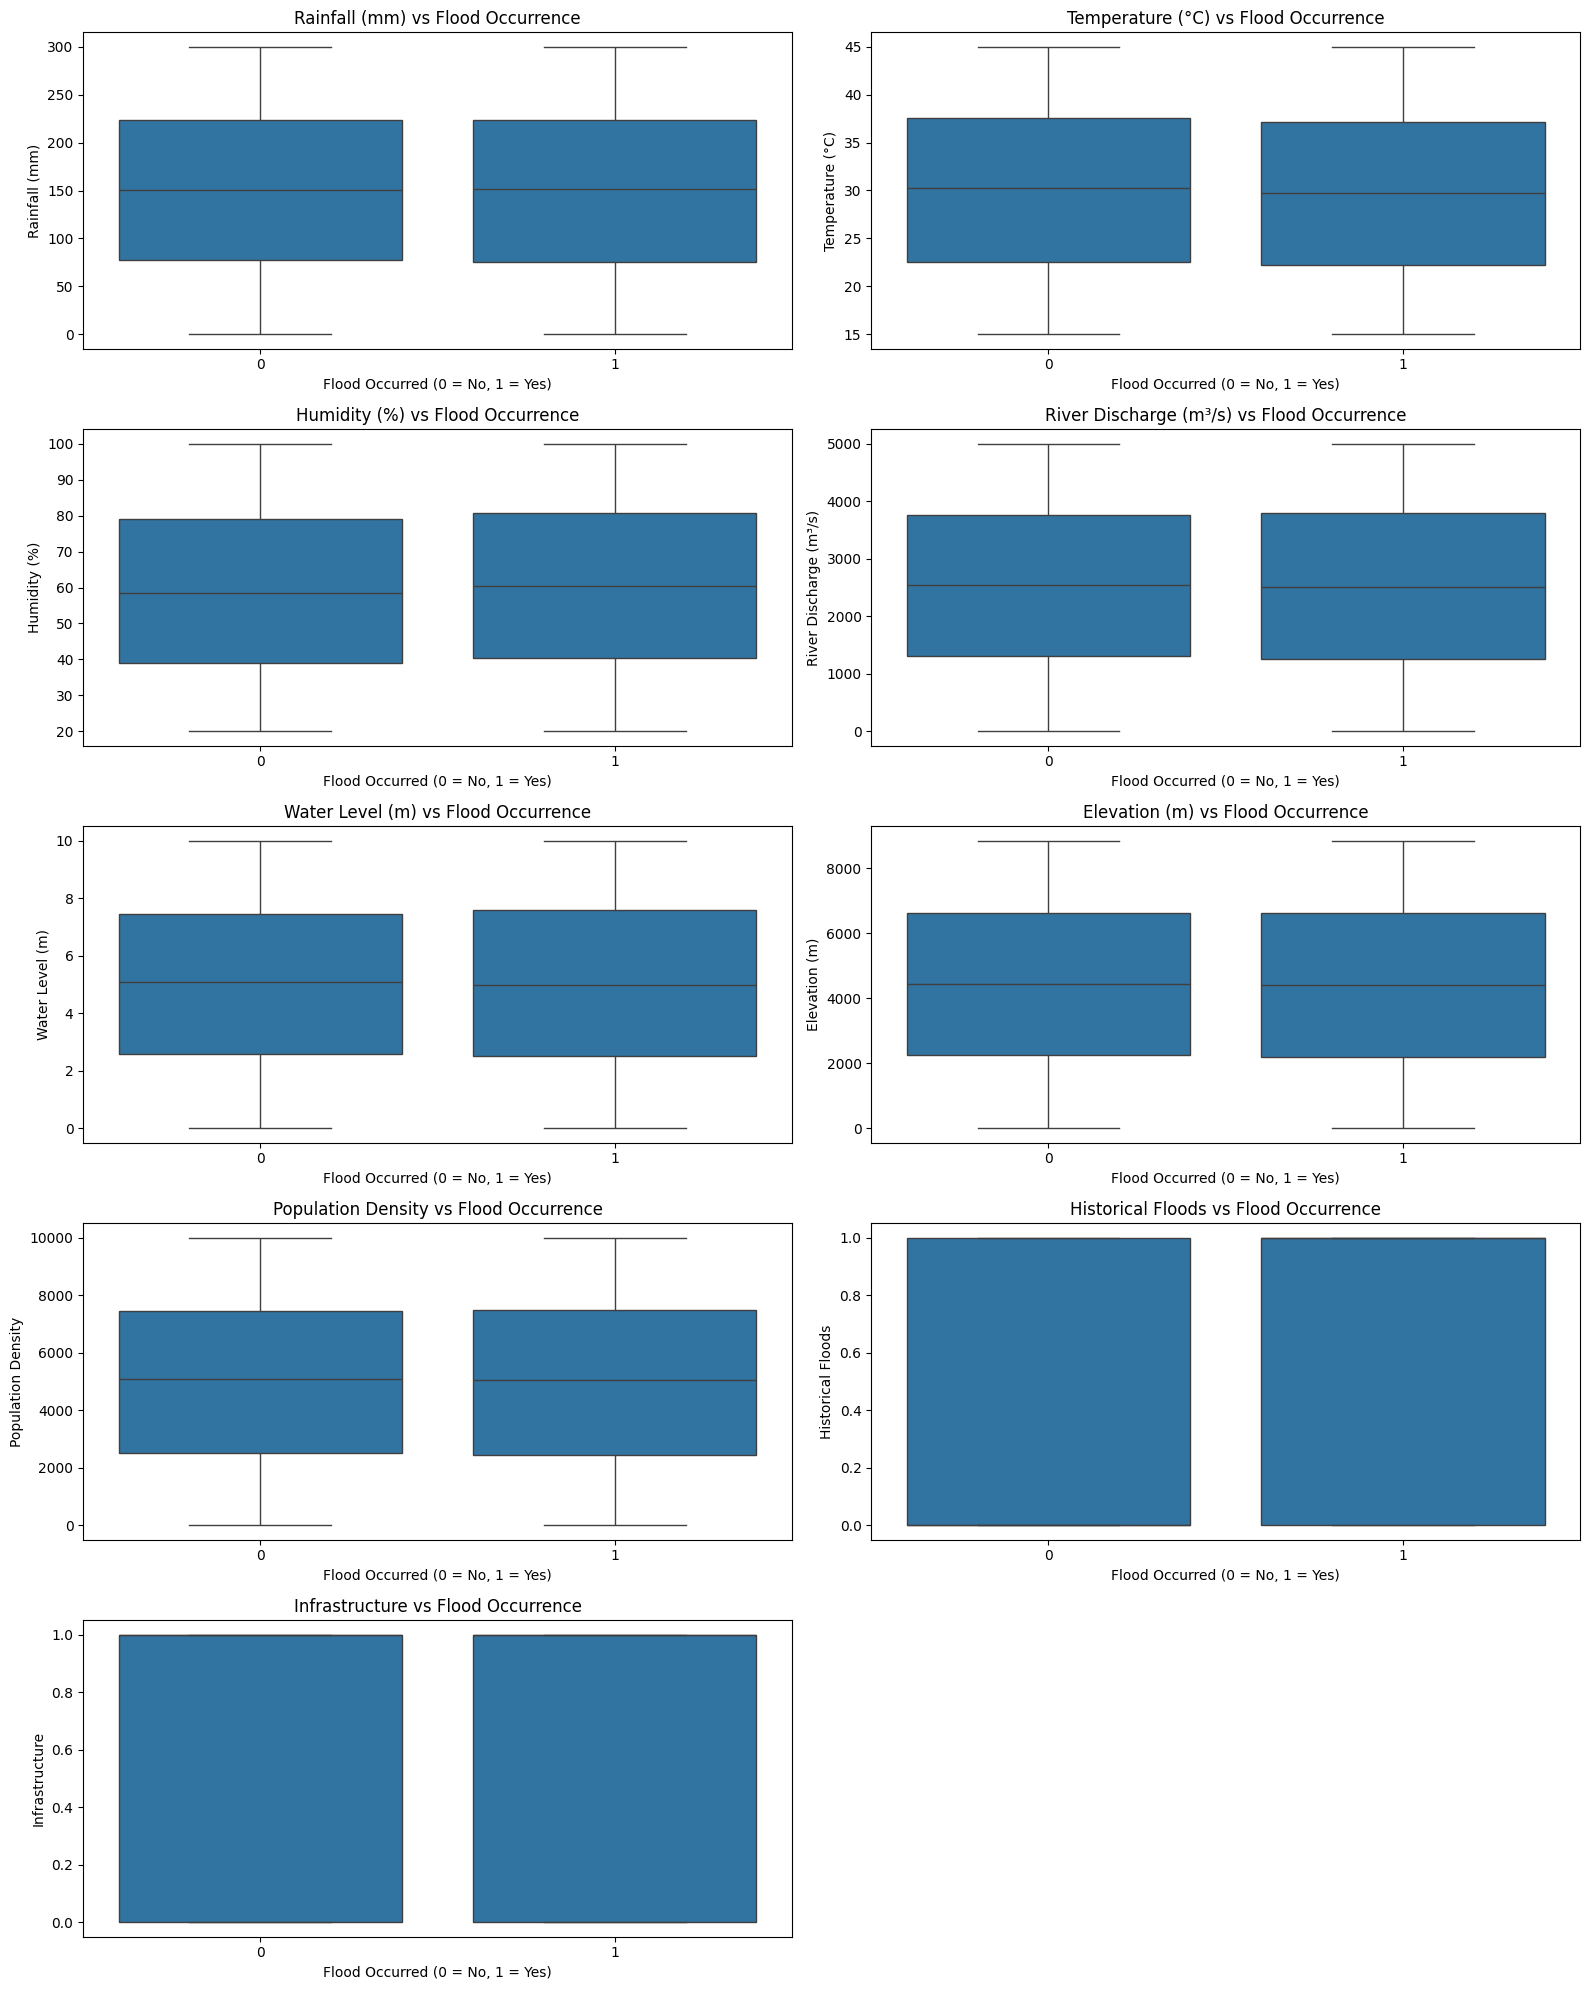

AVERAGE VALUES FOR FLOOD AND NO-FLOOD RECORDS


Flood Occurred,0,1
Rainfall (mm),150.203982,149.830512
Temperature (°C),30.099695,29.826225
Humidity (%),59.099478,60.384087
River Discharge (m³/s),2518.806972,2512.708443
Water Level (m),5.033043,5.003061
Elevation (m),4428.221616,4406.304591
Population Density,5036.067082,5007.198900
Historical Floods,0.492616,0.504647
Infrastructure,0.503945,0.500099


CORRELATION WITH FLOOD OCCURRENCE


,Flood Occurred
Flood Occurred,1.000000
Humidity (%),0.027754
Historical Floods,0.012030
Land Cover_Desert,0.010393
Land Cover_Urban,0.009591
Soil Type_Sandy,0.007497
Soil Type_Peat,0.005598
Land Cover_Forest,-0.001963
River Discharge (m³/s),-0.002115
Rainfall (mm),-0.002170


MISSING VALUES: 0
DUPLICATE ROWS: 0


In [143]:
# Complete Flood Prediction Data Analysis

features = [
    'Rainfall (mm)',
    'Temperature (°C)',
    'Humidity (%)',
    'River Discharge (m³/s)',
    'Water Level (m)',
    'Elevation (m)',
    'Population Density',
    'Historical Floods',
    'Infrastructure'
]

# Display all graphs together
plt.figure(figsize=(16, 20))

for i, feature in enumerate(features, 1):
    plt.subplot(5, 2, i)

    sns.boxplot(
        data=df,
        x='Flood Occurred',
        y=feature
    )

    plt.title(f'{feature} vs Flood Occurrence')
    plt.xlabel('Flood Occurred (0 = No, 1 = Yes)')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

# Compare average values
print("AVERAGE VALUES FOR FLOOD AND NO-FLOOD RECORDS")

display(
    df.groupby('Flood Occurred')[features].mean().T
)

# Correlation analysis
print("CORRELATION WITH FLOOD OCCURRENCE")

correlation = df.corr(numeric_only=True)['Flood Occurred']
display(correlation.sort_values(ascending=False))

# Check duplicate and missing values
print("MISSING VALUES:", df.isnull().sum().sum())
print("DUPLICATE ROWS:", df.duplicated().sum())

In [144]:
# Compare Different Machine Learning Models

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Define models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced')
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight='balanced', random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8,
        class_weight='balanced', random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, max_depth=8,
        class_weight='balanced', random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=2, random_state=42
    )
}

results = []

for name, algorithm in models.items():

    algorithm.fit(X_train, y_train)
    predictions = algorithm.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision": round(precision_score(y_test, predictions, zero_division=0), 3),
        "Recall": round(recall_score(y_test, predictions, zero_division=0), 3),
        "F1 Score": round(f1_score(y_test, predictions, zero_division=0), 3)
    })

results_df = pd.DataFrame(results)

print("MACHINE LEARNING MODEL COMPARISON")
display(results_df.sort_values(by="F1 Score", ascending=False))

MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy (%),Precision,Recall,F1 Score
4,Gradient Boosting,48.55,0.493,0.587,0.535
2,Random Forest,51.30,0.519,0.507,0.513
3,Extra Trees,49.15,0.497,0.513,0.505
0,Logistic Regression,49.65,0.502,0.505,0.504
1,Decision Tree,50.80,0.518,0.389,0.444


RANDOM FOREST FINAL RESULTS
Accuracy: 51.3 %

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.52      0.51       989
           1       0.52      0.51      0.51      1011

    accuracy                           0.51      2000
   macro avg       0.51      0.51      0.51      2000
weighted avg       0.51      0.51      0.51      2000



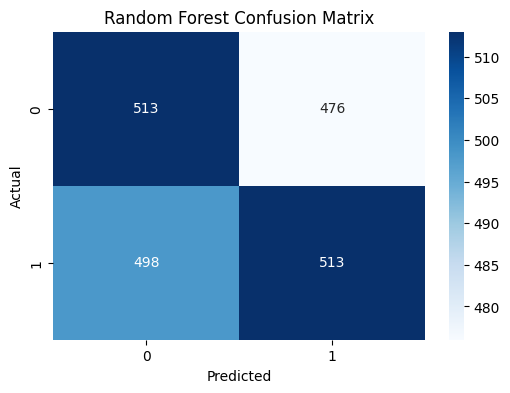

In [145]:
# Final Evaluation of Random Forest Model

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_model = models["Random Forest"]

y_pred = best_model.predict(X_test)

print("RANDOM FOREST FINAL RESULTS")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [146]:
# Updated Flood Prediction Website using Random Forest

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

# Use the selected Random Forest model
best_model = models["Random Forest"]

feature_names = X.columns.tolist()

def predict_flood(latitude, longitude, rainfall, temperature,
                  humidity, river_discharge, water_level,
                  elevation, population_density, infrastructure,
                  historical_floods, land_cover, soil_type):

    input_data = {
        'Latitude': latitude,
        'Longitude': longitude,
        'Rainfall (mm)': rainfall,
        'Temperature (°C)': temperature,
        'Humidity (%)': humidity,
        'River Discharge (m³/s)': river_discharge,
        'Water Level (m)': water_level,
        'Elevation (m)': elevation,
        'Population Density': population_density,
        'Infrastructure': infrastructure,
        'Historical Floods': historical_floods
    }

    for col in feature_names:
        if col.startswith('Land Cover_'):
            input_data[col] = int(col == f'Land Cover_{land_cover}')
        elif col.startswith('Soil Type_'):
            input_data[col] = int(col == f'Soil Type_{soil_type}')

    input_df = pd.DataFrame([input_data]).reindex(
        columns=feature_names, fill_value=0
    )

    prediction = best_model.predict(input_df)[0]
    probabilities = best_model.predict_proba(input_df)[0]

    confidence = max(probabilities) * 100

    if prediction == 1:
        result = "Flood predicted by the model"
    else:
        result = "No flood predicted by the model"

    return result, f"Model confidence: {confidence:.2f}%"

def show_dashboard():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    y.value_counts().sort_index().plot(
        kind='bar', ax=axes[0],
        title='Flood Occurrence Distribution'
    )
    axes[0].set_xlabel('Flood Occurred (0 = No, 1 = Yes)')
    axes[0].set_ylabel('Number of Records')

    importance = pd.Series(
        best_model.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(10)

    importance.sort_values().plot(
        kind='barh', ax=axes[1],
        title='Top 10 Important Features'
    )

    plt.tight_layout()
    return fig

with gr.Blocks(title="AI Flood Prediction System") as demo:

    gr.Markdown("# AI-Based Flood Prediction and Early Warning System")
    gr.Markdown("Enter environmental details to obtain a model prediction.")

    with gr.Row():
        with gr.Column():
            latitude = gr.Number(label="Latitude", value=13.0)
            longitude = gr.Number(label="Longitude", value=77.0)
            rainfall = gr.Number(label="Rainfall (mm)", value=100)
            temperature = gr.Number(label="Temperature (°C)", value=28)
            humidity = gr.Number(label="Humidity (%)", value=75)
            river_discharge = gr.Number(label="River Discharge (m³/s)", value=500)

        with gr.Column():
            water_level = gr.Number(label="Water Level (m)", value=5)
            elevation = gr.Number(label="Elevation (m)", value=800)
            population_density = gr.Number(label="Population Density", value=1000)
            infrastructure = gr.Number(label="Infrastructure", value=1)
            historical_floods = gr.Number(label="Historical Floods", value=1)

            land_cover = gr.Dropdown(
                choices=['Agricultural', 'Desert', 'Forest', 'Urban'],
                label="Land Cover", value='Urban'
            )
            soil_type = gr.Dropdown(
                choices=['Clay', 'Loamy', 'Sandy'],
                label="Soil Type", value='Clay'
            )

    predict_button = gr.Button("Predict Flood")

    prediction_output = gr.Textbox(label="Prediction Result")
    confidence_output = gr.Textbox(label="Model Confidence")

    predict_button.click(
        predict_flood,
        inputs=[
            latitude, longitude, rainfall, temperature,
            humidity, river_discharge, water_level,
            elevation, population_density, infrastructure,
            historical_floods, land_cover, soil_type
        ],
        outputs=[prediction_output, confidence_output]
    )

    gr.Markdown("## Flood Prediction Dashboard")
    dashboard_button = gr.Button("Show Dashboard")
    dashboard_output = gr.Plot()

    dashboard_button.click(
        show_dashboard,
        outputs=dashboard_output
    )

    gr.Markdown(
        "**Note:** Educational prototype only. "
        "The current model has limited predictive performance "
        "and must not be used for real-world emergency decisions."
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7e683a04ace3744322.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
